In [ ]:
import torch
import torch.nn as nn
lo
import numpy as np
import pandas as pd
import math
import copy
from tqdm.auto import tqdm

from torch.nn.functional import log_softmax, pad
from torch.utils.data import Dataset, DataLoader

In [ ]:
def attention(query, key, value, mask=None, dropout=None):
    d_k = query.size(-1)
    scores = torch.matmul(query, key.transpose(-1, -2)) / math.sqrt(d_k)

    if mask is not None:
        scores = scores.masked_fill(mask == 0, -1e9)
    p_attn = scores.softmax(dim=-1)
    if dropout is not None:
        p_attn = dropout(p_attn)

    return torch.matmul(p_attn, value), p_attn

In [ ]:
def clone(module, N):
    return nn.ModuleList([copy.deepcopy(module) for _ in range(N)])

In [ ]:
class MultiHeadAttention(nn.Module):
    def __init__(self, h, d_model, dropout=0.1):
        super(MultiHeadAttention, self).__init__()

        self.d_k = d_model // h
        self.h = h
        self.linears = clone(nn.Linear(d_model, d_model), 4)
        self.dropout = nn.Dropout(p=dropout)
        self.attn = None


    def forward(self, query, key, value, mask=None):
        if mask is not None:
            mask = mask.unsqueeze(1)
        nbatches = query.size(0)

        # к 3x512 применяем линейный слой, получаем 3x512, далее переделываем в (1,3,8,64) и потом меняем до (1,8,3,64)
        query, key, value = [lin(x).view(nbatches, -1, self.h, self.d_k).transpose(1,2) for lin, x in zip(self.linears, (query, key, value))]

        x, self_attn = attention(query, key, value, mask=mask, dropout=self.dropout)

        # здесь происходит обратная конкатенация 8 голов в 1 результат, т.е сначала поделили, вычислили attention, а потом обратно собираем
        x = (x.transpose(1,2).contiguous().view(nbatches, -1, self.h * self.d_k))

        del query
        del key
        del value
        return self.linears[-1](x) # линейный слой после конкатенации

In [ ]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, dropout, max_len=5000):
        super(PositionalEncoding, self).__init__()
        self.dropout = nn.Dropout(p=0.1)
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len).unsqueeze(1) # теперь это матричка (100,1)
        div_term = torch.exp(torch.arange(0, d_model, 2) * -(math.log(10000) / d_model))

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0)
        self.register_buffer("pe", pe)

    def forward(self, x):
        x = x + self.pe[:, :x.size(1)]
        return self.dropout(x)

In [ ]:
class PositionFeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dropout=0.1):
        super(PositionFeedForward, self).__init__()
        self.w1 = nn.Linear(d_model, d_ff)
        self.w2 = nn.Linear(d_ff, d_model)
        self.dropout = nn.Dropout(p=dropout)

    def forward(self, x):
        return self.w2(self.dropout(self.w1(x).relu()))

In [ ]:
class Embeddings(nn.Module):
    def __init__(self, d_model, vocab):
        super(Embeddings, self).__init__()
        self.emb = nn.Embedding(vocab, d_model)
        self.d_model = d_model
    def forward(self, x):
        return self.emb(x) * math.sqrt(self.d_model) # домножаем на sqrt(d_model)

In [ ]:
class LayerNorm(nn.Module):
    def __init__(self, features, eps=1e-6):
        super(LayerNorm, self).__init__()
        self.a = nn.Parameter(torch.ones(features))
        self.b = nn.Parameter(torch.zeros(features))
        self.eps = eps
    def forward(self, x):
        mean = x.mean(-1, keepdim=True) # у нас была размерность (2,3,512) и станет в mean = (2,3,1)
        std = x.std(-1, keepdim=True)
        return self.a * (x - mean) / (std + self.eps) + self.b

In [ ]:
class SublayerConnection(nn.Module):
    def __init__(self, size, dropout):
        super(SublayerConnection, self).__init__()
        self.norm = LayerNorm(size)
        self.dropout = nn.Dropout(p=dropout)
    def forward(self, x, sublayer):
        return x + self.dropout(sublayer(self.norm(x)))

In [ ]:
class EncoderLayer(nn.Module):
    def __init__(self, size, self_attn, feed_forward, dropout):
        super(EncoderLayer, self).__init__()
        self.self_attn = self_attn
        self.feed_forward = feed_forward
        self.sublayer = clone(SublayerConnection(size, dropout), 2)
        self.size = size


    def forward(self, x, mask):
        x = self.sublayer[0](x, lambda x: self.self_attn(x, x, x, mask)) # такая обёртка нужна, потому что self_attn ждёт 4 параметра, а не один как в feed_forward
        return self.sublayer[1](x, self.feed_forward)

In [ ]:
class Encoder(nn.Module):
    def __init__(self, layer, N):
        super(Encoder, self).__init__()
        self.layers = clone(layer, N)
        self.norm = LayerNorm(layer.size)
    def forward(self, x, mask):
        for layer in self.layers:
            x = layer(x, mask)
        return self.norm(x)

In [ ]:
class DecoderLayer(nn.Module):
    def __init__(self, size, self_attn, src_attn, feed_forward, dropout):
        super(DecoderLayer, self).__init__()
        self.self_attn = self_attn
        self.src_attn = src_attn
        self.size = size
        self.feed_forward = feed_forward
        self.sublayer = clone(SublayerConnection(size, dropout), 3)

    def forward(self, x, memory, src_mask, tgt_mask): # memory - выход encoder слоя, у src_mask размерность (B,1,T_src), у tgt_mask (B, T_tgt, T_tgt), T_src - длина вход предложения, T_tgt - выходного
        x = self.sublayer[0](x, lambda x: self.self_attn(x,x,x, tgt_mask))
        x = self.sublayer[1](x, lambda x: self.src_attn(x, memory, memory, src_mask))
        return self.sublayer[2](x, self.feed_forward)

In [ ]:
class Decoder(nn.Module):
    def __init__(self, layer, N):
        super(Decoder, self).__init__()
        self.layers = clone(layer, N)
        self.norm = LayerNorm(layer.size)
    def forward(self, x, memory, src_mask, tgt_mask):
        for layer in self.layers:
            x = layer(x, memory, src_mask, tgt_mask)
        return self.norm(x)

In [ ]:
class Generator(nn.Module):
    def __init__(self, d_model, vocab):
        super(Generator, self).__init__()
        self.proj = nn.Linear(d_model, vocab)
    def forward(self, x):
        return log_softmax(self.proj(x), dim=-1)

In [ ]:
class EncoderDecoder(nn.Module):
    def __init__(self, encoder, decoder, src_embed, tgt_embed, generator):
        super(EncoderDecoder, self).__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.src_embed = src_embed
        self.tgt_embed = tgt_embed
        self.generator = generator

    def forward(self, src, tgt, src_mask, tgt_mask):
        return self.decode(self.encode(src, src_mask), src_mask, tgt, tgt_mask)

    def encode(self, src, src_mask):
        return self.encoder(self.src_embed(src), src_mask)

    def decode(self, memory, src_mask, tgt, tgt_mask):
        return self.decoder(self.tgt_embed(tgt), memory, src_mask, tgt_mask)

In [ ]:
def make_model(src_vocab, tgt_vocab, N=6, d_model=512, d_ff=2048, h=8, dropout=0.1):
    c = copy.deepcopy
    attn = MultiHeadAttention(h, d_model)
    ff = PositionFeedForward(d_model, d_ff, dropout)
    position = PositionalEncoding(d_model, dropout)
    model = EncoderDecoder(
        Encoder(EncoderLayer(d_model, c(attn), c(ff), dropout), N),
        Decoder(DecoderLayer(d_model, c(attn), c(attn), c(ff), dropout), N),
        nn.Sequential(Embeddings(d_model, src_vocab), c(position)),
        nn.Sequential(Embeddings(d_model, tgt_vocab), c(position)),
        Generator(d_model, tgt_vocab)
    )

    for p in model.parameters():
        if p.dim() > 1:
            nn.init.xavier_uniform_(p)
    return model

In [ ]:
def show_example(fn, args=[]):
    if __name__ == "__main__" and RUN_EXAMPLES:
        return fn(*args)
RUN_EXAMPLES = True

In [ ]:
def subsequent_mask(size):
    attn_shape = (1, size, size)
    subsequent_mask = torch.triu(torch.ones(attn_shape), diagonal=1).type(
        torch.uint8
    )
    return subsequent_mask == 0

In [ ]:
def make_masks(src, tgt):
    # Padding mask для Encoder
    src_mask = (src != PAD).unsqueeze(1)

    # Padding mask для Decoder
    tgt_mask = (tgt != PAD).unsqueeze(1)

    tgt_mask[:, :, 0] = True

    # Causal mask: запрещаем смотреть в будущее
    tgt_mask = tgt_mask & subsequent_mask(tgt.size(1)).to(tgt.device)

    return src_mask, tgt_mask

In [ ]:
device = 'cuda' if torch.cuda.is_available() else 'сpu'
device

'cuda'

In [ ]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(
    "Helsinki-NLP/opus-mt-en-ru"
)

PAD = tokenizer.pad_token_id
EOS = tokenizer.eos_token_id
BOS = PAD  # Особенность Marian

In [ ]:
model = make_model(src_vocab=len(tokenizer), tgt_vocab=len(tokenizer)).to(device)
optimizer = torch.optim.Adam(model.parameters(),lr=3e-4)
loss_fn = nn.NLLLoss(ignore_index=PAD)

In [ ]:
def train_one_epoch(model, loader, optimizer, loss_fn):
    model.train()
    total_loss = 0.0

    for src, tgt in tqdm(loader):
        src = src.to(device)
        tgt = tgt.to(device)

        tgt_in = tgt[:,:-1]
        y = tgt[:, 1:]

        src_mask, tgt_mask = make_masks(src, tgt_in)

        optimizer.zero_grad()
        prohod = model(src, tgt_in, src_mask, tgt_mask)
        y_pred = model.generator(prohod)

        loss = loss_fn(y_pred.reshape(-1, y_pred.size(-1)), y.reshape(-1))

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(loader)




In [ ]:
@torch.no_grad()
def valid_one_epoch(model, loader, loss_fn):
    model.eval()
    total_loss = 0.0

    for src,tgt in tqdm(loader):
        src = src.to(device)
        tgt = tgt.to(device)

        tgt_in = tgt[:, :-1]
        y = tgt[:, 1:]

        src_mask, tgt_mask = make_masks(src, tgt_in)

        prohod = model(src, tgt_in, src_mask, tgt_mask)
        y_pred = model.generator(prohod)

        loss = loss_fn(y_pred.reshape(-1, y_pred.size(-1)), y.reshape(-1))

        total_loss += loss.item()

    return total_loss / len(loader)

In [ ]:
!pip install datasets

In [ ]:
from datasets import load_dataset
from torch.utils.data import DataLoader

data = load_dataset(
    "Helsinki-NLP/opus-100",
    "en-ru",
    split="train[:5000]"
)

splits = data.train_test_split(
    test_size=0.1,
    seed=42
)

train_dataset = splits["train"]
valid_dataset = splits["test"]

In [ ]:
from torch.nn.utils.rnn import pad_sequence

MAX_LEN = 32
BATCH_SIZE = 8

def collate_fn(batch):
    en = [item["translation"]["en"] for item in batch]
    ru = [item["translation"]["ru"] for item in batch]

    src = tokenizer(
        en,
        padding=True,
        truncation=True,
        max_length=MAX_LEN,
        return_tensors="pt"
    )["input_ids"]

    tgt_ids = tokenizer(
        text_target=ru,
        truncation=True,
        max_length=MAX_LEN - 1
    )["input_ids"]

    tgt = [
        torch.tensor([BOS] + ids, dtype=torch.long)
        for ids in tgt_ids
    ]

    tgt = pad_sequence(
        tgt,
        batch_first=True,
        padding_value=PAD
    )

    return src, tgt

In [ ]:
train_dataloader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    collate_fn=collate_fn
)

valid_dataloader = DataLoader(
    valid_dataset,
    batch_size=32,
    shuffle=False,
    collate_fn=collate_fn
)

In [ ]:
train_losses = []
valid_losses = []

for epoch in tqdm(range(5)):
    train_loss = train_one_epoch(
        model, train_dataloader, optimizer, loss_fn
    )

    valid_loss = valid_one_epoch(
        model, valid_dataloader, loss_fn
    )
    train_losses.append(train_loss)
    valid_losses.append(valid_loss)
    print(
        f"Epoch {epoch + 1} |"
        f"train_loss={train_loss:.3f} |"
        f"valid_loss={valid_loss:.3f}"
    )

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/141 [00:00<?, ?it/s]

  0%|          | 0/16 [00:00<?, ?it/s]

Epoch 1 |train_loss=7.639 |valid_loss=7.021


  0%|          | 0/141 [00:00<?, ?it/s]

...

  0%|          | 0/16 [00:00<?, ?it/s]

Epoch 4 |train_loss=5.790 |valid_loss=6.690


  0%|          | 0/141 [00:00<?, ?it/s]

  0%|          | 0/16 [00:00<?, ?it/s]

Epoch 5 |train_loss=5.483 |valid_loss=6.687


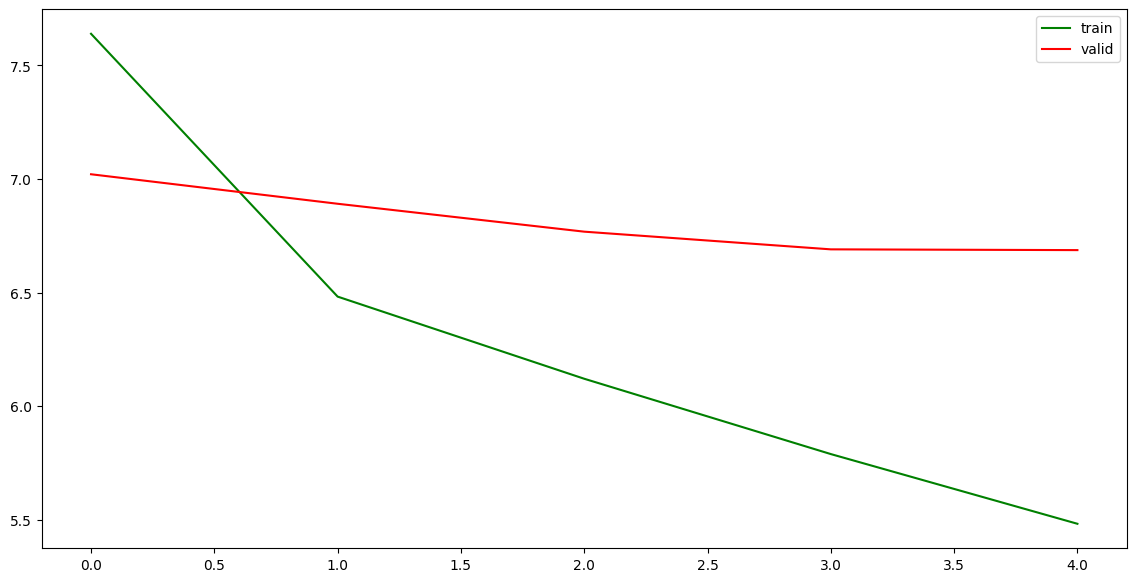

In [ ]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(14,7))
ax = plt.subplot(111)

plt.plot(train_losses, c='green', label='train')
plt.plot(valid_losses, c='red', label='valid')

plt.legend()
plt.show()